# Appendix: figures and diagrams

Question: what do the study design, the model and the results look like when every figure is drawn from the saved files?

What enters: the tables of notebooks 1 and 2, and the fold files, comparison rows, training curves, final models and METABRIC scores of notebook 3. Nothing is fitted or trained here; the survival curves of the last figure are read from the follow-up columns of the two cohort tables.

What leaves: one PNG file per figure in `results/appendix_figures_and_diagrams/`.

How to run: the nbconvert command of notebook 1; under a minute.

In [1]:
import hashlib
import json
import subprocess
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.patches import FancyBboxPatch
from sksurv.nonparametric import kaplan_meier_estimator

## Settings

The paths, the resolution of the saved files and the few constants the figures need are set here once.

In [2]:
RESULTS = Path("../results")
DATA = Path("../data/processed")
PIPELINE = RESULTS / "03_pipeline"
OUT = RESULTS / "appendix_figures_and_diagrams"
DPI = 150                    # resolution of the saved PNG files
LAYOUT_SEED = 0              # the spring layout of the gene graph starts from this seed
LAYERS = ["GraphSAGE", "GCN", "GIN", "GATv2"]  # the four layer types of notebook 3
CUTOFFS = [700, 400]         # the STRING score cut-offs of the graph rows
REGISTERED_RATE = 0.001      # the registered learning rate of notebook 3
REGISTERED_UPDATES = 40      # the registered number of training updates of notebook 3
DAYS_PER_YEAR = 365.25       # follow-up is stored in days
AT_RISK_YEARS = [0, 5, 10, 15, 20]  # times at which the patients still followed are counted
OUT.mkdir(exist_ok=True)
style = {"font.size": 9, "axes.spines.top": False, "axes.spines.right": False}
plt.rcParams.update(style)

## The saved files

Every figure below reads only these files. The two checks tie the frozen model to its saved gene list and confirm the five outer folds.

In [3]:
cohort_tcga = pd.read_csv(RESULTS / "01_data" / "cohort_tcga.csv")
cohort_metabric = pd.read_csv(RESULTS / "01_data" / "cohort_metabric.csv")
graph_summary = pd.read_csv(RESULTS / "02_gene_graph" / "graph_summary.csv", index_col=0)
string_release = pd.read_csv(RESULTS / "02_gene_graph" / "sources.csv")["release"].iloc[0]
symbols = pd.read_csv(RESULTS / "01_data" / "gene_pool.csv", index_col="gene_id")["symbol"]
edge_lists = {}
for cutoff in CUTOFFS:
    edge_lists[cutoff] = pd.read_csv(RESULTS / "02_gene_graph" / f"edges_{cutoff}.csv.gz")
fold_records = []
fold_genes = []
for number in range(1, 6):
    fold_records.append(json.loads((PIPELINE / f"outer_fold_{number}.json").read_text()))
    fold_genes.append((PIPELINE / f"outer_fold_{number}_genes.txt").read_text().split())
summary = pd.read_csv(PIPELINE / "summary.csv", index_col=0)["value"]
paired = pd.read_csv(PIPELINE / "comparison_paired.csv", index_col=0)
by_fold = pd.read_csv(PIPELINE / "comparison_by_fold.csv")
fold_edges = pd.read_csv(PIPELINE / "graph_question_edges.csv", index_col="outer fold")
final_genes = (PIPELINE / "final_model" / "final_genes.txt").read_text().split()
final_saved = torch.load(PIPELINE / "final_model" / "model.pt", weights_only=False)
final_models = pd.read_csv(PIPELINE / "final_models.csv", index_col="row")
metabric_scores = pd.read_csv(PIPELINE / "metabric" / "scores.csv", index_col=0)
metabric_paired = pd.read_csv(PIPELINE / "metabric" / "paired.csv", index_col=0)
assert len(fold_records) == 5, "the five outer folds of notebook 3 are expected"
assert final_saved["genes"] == final_genes, "the frozen model holds the saved final gene list"
display(Markdown(f"Read {len(fold_records)} outer folds, {len(paired)} paired comparisons on TCGA, "
                 f"{len(metabric_scores)} models scored on METABRIC and {len(final_genes)} final "
                 f"genes; the gene graph is {string_release}."))

Read 5 outer folds, 71 paired comparisons on TCGA, 20 models scored on METABRIC and 450 final genes; the gene graph is STRING 12.5.

## Drawing helpers

Small functions draw the boxes, arrows and interval plots that the figures share, and save each figure.

In [4]:
def box(axis, centre, size, text, colour):
    """A rounded box with centred text; centre and size in the axis units of 0 to 10."""
    left = centre[0] - size[0] / 2
    bottom = centre[1] - size[1] / 2
    patch = FancyBboxPatch((left, bottom), size[0], size[1], boxstyle="round,pad=0.02",
                           facecolor=colour, edgecolor="black", linewidth=0.8)
    axis.add_patch(patch)
    axis.text(centre[0], centre[1], text, ha="center", va="center", fontsize=8)


def arrow(axis, start, end):
    """An arrow from one point to another."""
    props = {"arrowstyle": "->", "linewidth": 1}
    axis.annotate("", xy=end, xytext=start, arrowprops=props)


def blank(width, height):
    """A figure with one axis without ticks, drawn in units of 0 to 10 on both sides."""
    figure, axis = plt.subplots(figsize=(width, height))
    axis.set_xlim(0, 10)
    axis.set_ylim(0, 10)
    axis.axis("off")
    return figure, axis

In [5]:
def save(figure, name):
    """Save a figure as a PNG file in this notebook's results folder and show it."""
    metadata = {"Software": None}  # no version stamp, so a re-run writes the same bytes
    figure.savefig(OUT / f"{name}.png", dpi=DPI, bbox_inches="tight", metadata=metadata)
    plt.show()


def intervals(axis, rows, title):
    """One row per comparison: its mean difference with the interval, and a dashed line at 0."""
    positions = np.arange(len(rows))[::-1]
    below = rows["mean difference"] - rows["lower"]
    above = rows["upper"] - rows["mean difference"]
    axis.errorbar(rows["mean difference"], positions, xerr=[below, above], fmt="o",
                  color="#2f6f9f", markersize=3.5, capsize=2, linewidth=1)
    axis.axvline(0, color="black", linewidth=0.8, linestyle="--")
    axis.set_yticks(positions, rows.index, fontsize=7)
    axis.set_title(title, fontsize=9)

### Figure 1: from public data to results

The notebooks in the order they run, what each reads and what it writes. The counts in the boxes are read from each notebook's result files.

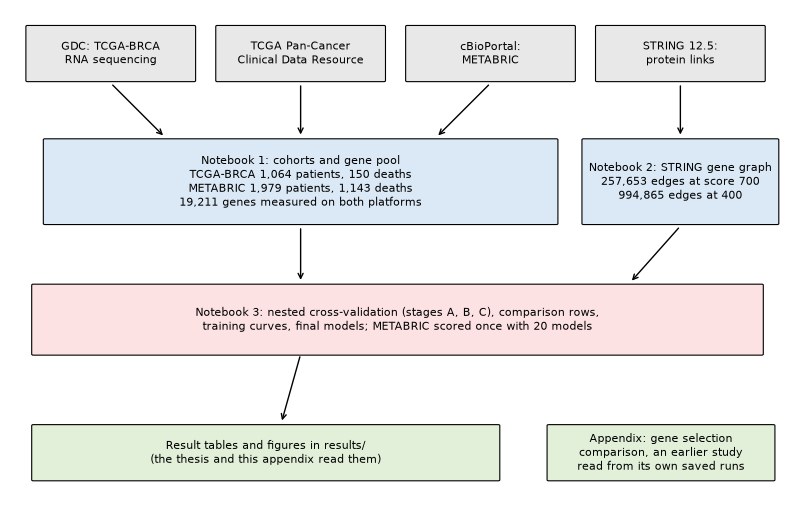

In [6]:
FLOW_ARROWS = [((1.3, 8.5), (2.0, 7.4)), ((3.75, 8.5), (3.75, 7.4)), ((6.2, 8.5), (5.5, 7.4)),
               ((8.65, 8.5), (8.65, 7.4)), ((3.75, 5.6), (3.75, 4.45)), ((8.65, 5.6), (8.0, 4.45)),
               ((3.75, 3.0), (3.5, 1.6))]  # from box edge to box edge, in the diagram's units


def data_flow():
    """Sources, notebooks and outputs, with counts read from the notebooks' files."""
    figure, axis = blank(10, 6.4)
    tcga = cohort_tcga.iloc[-1]
    metabric = cohort_metabric.iloc[-1]
    sources = ["GDC: TCGA-BRCA\nRNA sequencing", "TCGA Pan-Cancer\nClinical Data Resource",
               "cBioPortal:\nMETABRIC", f"{string_release}:\nprotein links"]
    for position, text in enumerate(sources):
        box(axis, (1.3 + position * 2.45, 9.1), (2.15, 1.1), text, "#e8e8e8")
    first = (f"Notebook 1: cohorts and gene pool\nTCGA-BRCA {tcga['patients']:,} patients, "
             f"{tcga['deaths']:,} deaths\nMETABRIC {metabric['patients']:,} patients, "
             f"{metabric['deaths']:,} deaths\n{graph_summary['pool genes'].iloc[0]:,} genes "
             "measured on both platforms")
    box(axis, (3.75, 6.5), (6.6, 1.7), first, "#dbe9f6")
    second = (f"Notebook 2: STRING gene graph\n{graph_summary.loc['score >= 700', 'edges']:,} "
              f"edges at score 700\n{graph_summary.loc['score >= 400', 'edges']:,} edges at 400")
    box(axis, (8.65, 6.5), (2.5, 1.7), second, "#dbe9f6")
    third = ("Notebook 3: nested cross-validation (stages A, B, C), comparison rows,\n"
             f"training curves, final models; METABRIC scored once with {len(metabric_scores)} "
             "models")
    box(axis, (5, 3.7), (9.4, 1.4), third, "#fde2e4")
    box(axis, (3.3, 1.0), (6.0, 1.1), "Result tables and figures in results/\n(the thesis and "
        "this appendix read them)", "#e2f0d9")
    box(axis, (8.4, 1.0), (2.9, 1.1), "Appendix: gene selection\ncomparison, an earlier study\n"
        "read from its own saved runs", "#e2f0d9")
    for start, end in FLOW_ARROWS:
        arrow(axis, start, end)
    return figure


save(data_flow(), "figure_01_data_flow")

### Figure 2: who is in the two cohorts

Each rule of notebook 1 in order, with the patients and deaths it leaves. Look at the last box of each column: these are the cohorts every model uses.

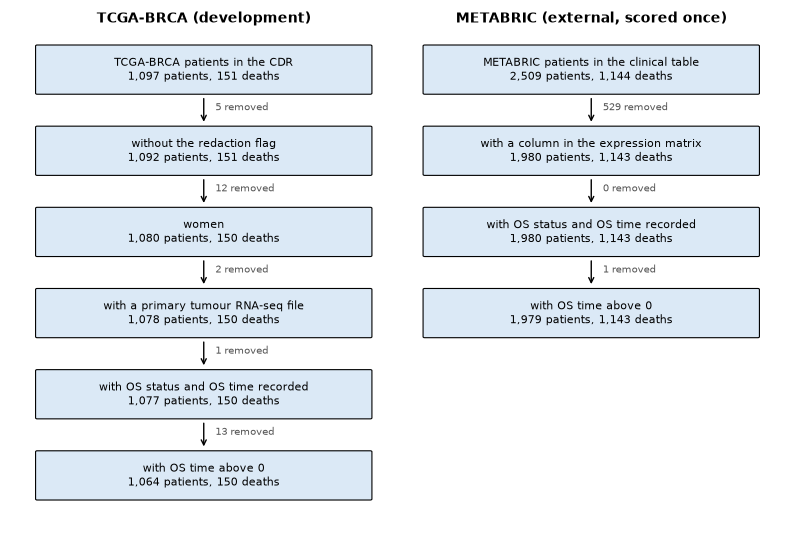

In [7]:
def cohort_column(axis, table, x, title):
    """One cohort's rules from top to bottom, with the patients each rule removes."""
    axis.text(x, 9.75, title, ha="center", fontsize=10, weight="bold")
    step = 1.55  # the same spacing in both columns
    for position, row in enumerate(table.itertuples()):
        y = 8.85 - position * step
        box(axis, (x, y), (4.3, 0.9), f"{row.rule}\n{row.patients:,} patients, "
            f"{row.deaths:,} deaths", "#dbe9f6")
        if position:
            removed = table["patients"].iloc[position - 1] - row.patients
            arrow(axis, (x, y + step - 0.5), (x, y + 0.5))
            axis.text(x + 0.15, y + step / 2, f"{removed:,} removed", fontsize=7, color="#555")


figure, axis = blank(10, 6.8)
cohort_column(axis, cohort_tcga, 2.5, "TCGA-BRCA (development)")
cohort_column(axis, cohort_metabric, 7.5, "METABRIC (external, scored once)")
save(figure, "figure_02_cohorts")

### Figure 3: how the patients are split

Nested cross-validation as notebook 3 runs it. Each outer test part (dark) is scored once; everything the model learns comes from the outer training part, whose five inner folds choose the settings. Look at the patient counts: they are read from the fold files.

In [8]:
def outer_folds(axis):
    """The five outer folds: training parts in light blue, the test part in dark blue."""
    axis.text(0.1, 9.6, "Outer loop: five folds, each test part scored once", fontsize=9,
              weight="bold")
    for index, record in enumerate(fold_records):
        y = 8.7 - index * 0.75
        for block in range(5):
            colour = "#2f6f9f" if block == index else "#c9dcee"
            axis.add_patch(plt.Rectangle((0.2 + block * 0.6, y), 0.55, 0.5, color=colour))
        counts = record["patients"]
        axis.text(3.4, y + 0.25, f"fold {index + 1}: train {counts['training']}, test "
                  f"{counts['test']} ({counts['test deaths']} deaths)", va="center", fontsize=7.5)


def inner_folds(axis):
    """Inside one outer training part: five inner folds, the validation part in green."""
    axis.text(6.2, 9.6, "Inner loop: five folds inside the training part", fontsize=9,
              weight="bold")
    axis.text(6.2, 9.25, "(the training part of every outer fold is split again)", fontsize=7.5)
    for index in range(5):
        y = 8.7 - index * 0.75
        for block in range(5):
            colour = "#3a8d4f" if block == index else "#d9d9d9"
            axis.add_patch(plt.Rectangle((6.3 + block * 0.6, y), 0.55, 0.5, color=colour))
        axis.text(9.4, y + 0.25, f"inner {index + 1}", va="center", fontsize=7.5)
    key = [("#2f6f9f", "outer test part"), ("#c9dcee", "outer training part"),
           ("#3a8d4f", "inner validation part"), ("#d9d9d9", "inner fit part")]
    for position, (colour, label) in enumerate(key):
        axis.add_patch(plt.Rectangle((0.2 + position * 2.5, 4.85), 0.3, 0.3, color=colour))
        axis.text(0.6 + position * 2.5, 5.0, label, va="center", fontsize=7.5)

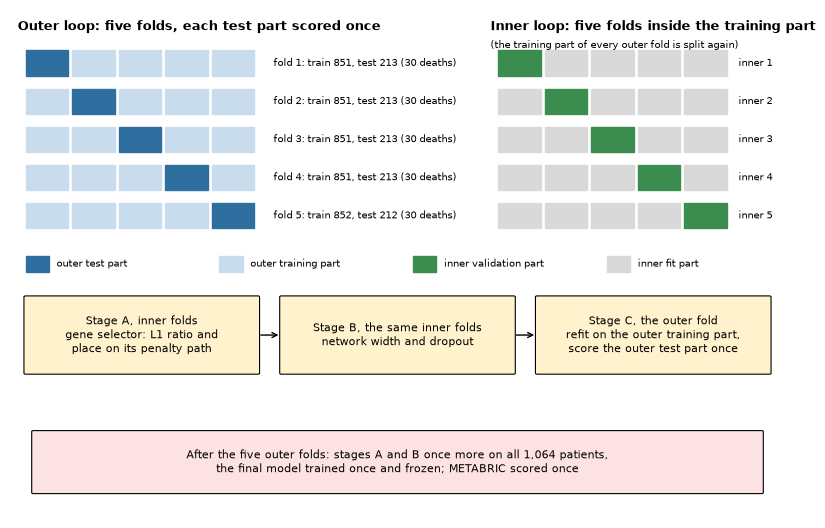

The five test parts hold 1064 patients, each patient exactly once.

In [9]:
def stages(axis):
    """Stages A, B and C, the final model and the one METABRIC scoring."""
    steps = [("Stage A, inner folds\ngene selector: L1 ratio and\nplace on its penalty path",
              (1.7, 3.6)),
             ("Stage B, the same inner folds\nnetwork width and dropout", (5.0, 3.6)),
             ("Stage C, the outer fold\nrefit on the outer training part,\nscore the outer test "
              "part once", (8.3, 3.6))]
    for text, centre in steps:
        box(axis, centre, (3.0, 1.5), text, "#fff2cc")
    arrow(axis, (3.2, 3.6), (3.5, 3.6))
    arrow(axis, (6.5, 3.6), (6.8, 3.6))
    patients = fold_records[0]["patients"]["training"] + fold_records[0]["patients"]["test"]
    text = (f"After the five outer folds: stages A and B once more on all {patients:,} "
            "patients,\nthe final model trained once and frozen; METABRIC scored once")
    box(axis, (5.0, 1.1), (9.4, 1.2), text, "#fde2e4")


figure, axis = blank(10, 6.6)
outer_folds(axis)
inner_folds(axis)
stages(axis)
save(figure, "figure_03_nested_cross_validation")
total = sum(record["patients"]["test"] for record in fold_records)
assert total == cohort_tcga["patients"].iloc[-1], "the test parts cover the cohort exactly once"
display(Markdown(f"The five test parts hold {total} patients, each patient exactly once."))

### Figure 4: the registered graph model, layer by layer

The sizes are read from the tensors of the frozen final model, and the checks compare them with the model's saved settings. The patient graph has one node per selected gene and one number per node.

In [10]:
state = final_saved["state"]
width = state["layer_1.lin_l.weight"].shape[0]
node_features = state["layer_1.lin_l.weight"].shape[1]
head_inputs = state["head.0.weight"].shape[1]
level_count = 0
for levels in final_saved["clinical levels"].values():
    level_count += len(levels)
clinical_size = 1 + level_count  # age, then one column per level of stage, ER, PR and HER2
assert width == final_saved["hidden size"], "the tensors have the saved width"
assert head_inputs == width + clinical_size, "the head reads the pooled and the clinical vector"
assert state["head.3.weight"].shape == (1, width), "the head ends in one log-hazard"
final_700 = edge_lists[700]
both_final = final_700["gene_a"].isin(final_genes) & final_700["gene_b"].isin(final_genes)
final_edges = final_700[both_final]
display(Markdown(f"Width {width}, {node_features} feature per node, clinical vector of "
                 f"{clinical_size} numbers, {len(final_genes)} genes and {len(final_edges)} STRING "
                 "edges at 700 in the final model."))

Width 64, 1 feature per node, clinical vector of 15 numbers, 450 genes and 122 STRING edges at 700 in the final model.

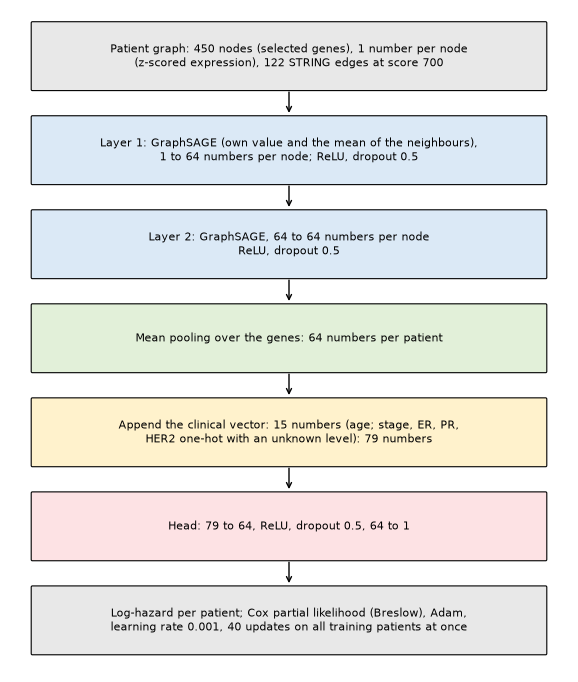

In [11]:
def architecture():
    """The registered model from the patient graph to the log-hazard, with the saved sizes."""
    figure, axis = blank(7.2, 8.6)
    dropout = final_saved["dropout"]
    steps = [(f"Patient graph: {len(final_genes)} nodes (selected genes), "
              f"{node_features} number per node\n(z-scored expression), {len(final_edges)} "
              "STRING edges at score 700", "#e8e8e8"),
             (f"Layer 1: GraphSAGE (own value and the mean of the neighbours),\n{node_features} "
              f"to {width} numbers per node; ReLU, dropout {dropout}", "#dbe9f6"),
             (f"Layer 2: GraphSAGE, {width} to {width} numbers per node\nReLU, dropout "
              f"{dropout}", "#dbe9f6"),
             (f"Mean pooling over the genes: {width} numbers per patient", "#e2f0d9"),
             (f"Append the clinical vector: {clinical_size} numbers (age; stage, ER, PR,\n"
              f"HER2 one-hot with an unknown level): {head_inputs} numbers", "#fff2cc"),
             (f"Head: {head_inputs} to {width}, ReLU, dropout {dropout}, {width} to 1",
              "#fde2e4"),
             ("Log-hazard per patient; Cox partial likelihood (Breslow), Adam,\nlearning rate "
              f"{REGISTERED_RATE}, {REGISTERED_UPDATES} updates on all training patients at once",
              "#e8e8e8")]
    for index, (text, colour) in enumerate(steps):
        y = 9.3 - index * 1.42
        box(axis, (5, y), (9.2, 1.0), text, colour)
        if index:
            arrow(axis, (5, y + 0.92), (5, y + 0.52))
    return figure


save(architecture(), "figure_04_model_architecture")

The four layer types differ in how a node combines its neighbours, so their final models differ in size. The table counts the learned numbers of each final model, read from the saved tensors, beside the width and dropout it chose.

In [12]:
def parameter_count(path):
    """The number of learned values in one saved model."""
    count = 0
    for tensor in torch.load(path, weights_only=False)["state"].values():
        count += tensor.numel()
    return count


sizes = final_models[["hidden size", "dropout"]].copy()
for row in sizes.index:
    folder = row.lower().replace(", ", "_").replace(" ", "_")
    sizes.loc[row, "parameters"] = parameter_count(PIPELINE / "final_models" / folder / "model.pt")
sizes.loc["graph model (registered)"] = [width, final_saved["dropout"],
                                         parameter_count(PIPELINE / "final_model" / "model.pt")]
sizes["parameters"] = sizes["parameters"].astype(int)
display(sizes)

,hidden size,dropout,parameters
row,,,
"GraphSAGE, STRING 700",64.0,0.5,13633
"GraphSAGE, STRING 700, edges removed",64.0,0.5,13633
"GraphSAGE, STRING 400",64.0,0.5,13633
"GraphSAGE, STRING 400, edges removed",64.0,0.5,13633
"GCN, STRING 700",64.0,0.5,9473
"GCN, STRING 700, edges removed",64.0,0.5,9473
"GCN, STRING 400",128.0,0.5,35329
"GCN, STRING 400, edges removed",128.0,0.5,35329
"GIN, STRING 700",128.0,0.2,68355


### Figure 5: the final gene graph at the two cut-offs

The final model's genes as nodes and the STRING edges among them. Grey nodes have no edge; in every layer type such a node only transforms its own expression. Look at the share of grey nodes at each cut-off.

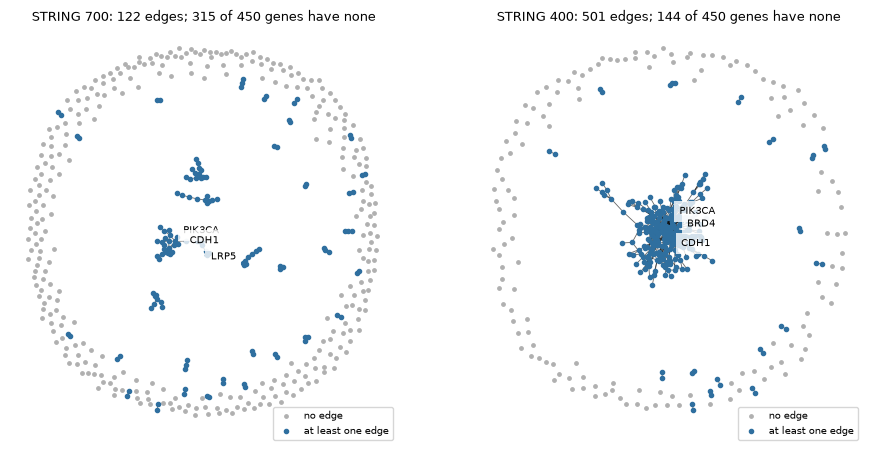

In [13]:
def gene_graph(cutoff):
    """The final genes as nodes and the STRING edges among them at one cut-off."""
    edges = edge_lists[cutoff]
    kept = edges[edges["gene_a"].isin(final_genes) & edges["gene_b"].isin(final_genes)]
    graph = nx.Graph()
    graph.add_nodes_from(final_genes)
    graph.add_edges_from(zip(kept["gene_a"], kept["gene_b"]))
    return graph


def draw_graph(axis, cutoff):
    """One cut-off's graph: connected genes in blue, isolated genes in grey, hubs named."""
    graph = gene_graph(cutoff)
    layout = nx.spring_layout(graph, seed=LAYOUT_SEED)
    isolated = list(nx.isolates(graph))
    connected = [gene for gene in graph.nodes if gene not in set(isolated)]
    nx.draw_networkx_edges(graph, layout, ax=axis, width=0.6, alpha=0.6)
    nx.draw_networkx_nodes(graph, layout, nodelist=isolated, node_size=6, node_color="#b0b0b0",
                           ax=axis, label="no edge")
    nx.draw_networkx_nodes(graph, layout, nodelist=connected, node_size=9, node_color="#2f6f9f",
                           ax=axis, label="at least one edge")
    hubs = sorted(graph.degree, key=lambda pair: pair[1], reverse=True)[:3]
    label_box = {"facecolor": "white", "alpha": 0.8, "linewidth": 0}
    for offset, (gene, _) in enumerate(hubs):
        x, y = layout[gene]
        axis.text(x + 0.08, y + 0.08 - offset * 0.09, symbols.get(gene, gene), fontsize=7,
                  bbox=label_box)
    axis.legend(fontsize=7, loc="lower right")
    axis.set_title(f"STRING {cutoff}: {graph.number_of_edges()} edges; {len(isolated)} of "
                   f"{graph.number_of_nodes()} genes have none", fontsize=9)
    axis.axis("off")
    return len(isolated)


figure, axes = plt.subplots(1, 2, figsize=(11, 5.4))
isolated_counts = {}
for axis, cutoff in zip(axes, CUTOFFS):
    isolated_counts[cutoff] = draw_graph(axis, cutoff)
save(figure, "figure_05_final_gene_graph")

### Figure 6: what the cut-off does to the graph

Left: the whole gene pool at the three STRING cut-offs of notebook 2. Right: the gene lists selected in the five outer folds, with the share of genes that have at least one edge. The selected lists inherit STRING's sparsity at 700.

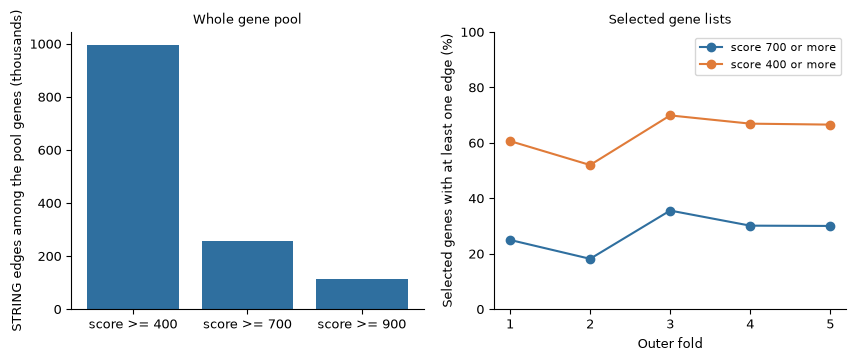

In [14]:
def fold_graph_counts():
    """Per outer fold and cut-off: the selected genes, their edges and the genes with an edge."""
    rows = []
    for number, genes in enumerate(fold_genes, start=1):
        for cutoff in CUTOFFS:
            edges = edge_lists[cutoff]
            kept = edges[edges["gene_a"].isin(genes) & edges["gene_b"].isin(genes)]
            linked = set(kept["gene_a"]) | set(kept["gene_b"])
            row = {"outer fold": number, "cut-off": cutoff, "genes": len(genes),
                   "edges": len(kept), "share with an edge": len(linked) / len(genes)}
            rows.append(row)
    return pd.DataFrame(rows)


counts = fold_graph_counts()
for cutoff in CUTOFFS:
    saved_edges = fold_edges[f"edges at {cutoff}"].to_numpy()
    computed = counts.loc[counts["cut-off"] == cutoff, "edges"].to_numpy()
    assert (saved_edges == computed).all(), "the edge counts equal notebook 3's saved table"
figure, axes = plt.subplots(1, 2, figsize=(10, 3.6))
pool = graph_summary["edges"] / 1000
axes[0].bar(graph_summary.index, pool, color="#2f6f9f")
axes[0].set_ylabel("STRING edges among the pool genes (thousands)")
axes[0].set_title("Whole gene pool", fontsize=9)
for cutoff, colour in zip(CUTOFFS, ["#2f6f9f", "#e07b39"]):
    part = counts[counts["cut-off"] == cutoff]
    axes[1].plot(part["outer fold"], part["share with an edge"] * 100, "o-", color=colour,
                 label=f"score {cutoff} or more")
axes[1].set_ylim(0, 100)
axes[1].set_xticks(range(1, 6))
axes[1].set_xlabel("Outer fold")
axes[1].set_ylabel("Selected genes with at least one edge (%)")
axes[1].set_title("Selected gene lists", fontsize=9)
axes[1].legend(fontsize=8)
save(figure, "figure_06_string_cut_off")

### Figure 7: the score of every registered row in every fold

One dot per outer fold and a bar at the mean, Harrell's C on the outer test parts. Look at how far the dots of one row spread compared with the distance between row means: this spread is why the paired intervals are wide.

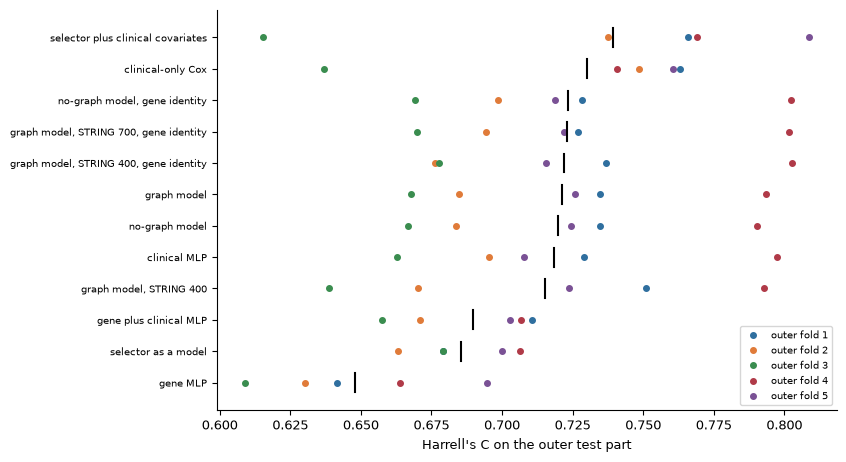

Row means run from 0.648 to 0.739; the five folds of one row span 0.043 to 0.193.

In [15]:
earlier = by_fold[~by_fold["model"].str.split(",").str[0].isin(LAYERS)]
order = earlier.groupby("model")["Harrell's C"].mean().sort_values().index
figure, axis = plt.subplots(figsize=(8, 5.2))
fold_colours = ["#2f6f9f", "#e07b39", "#3a8d4f", "#b03a48", "#7a5195"]
for position, model in enumerate(order):
    part = earlier[earlier["model"] == model]
    for fold, colour in zip(range(1, 6), fold_colours):
        score = part.loc[part["outer fold"] == fold, "Harrell's C"]
        label = f"outer fold {fold}" if position == 0 else None
        axis.plot(score, [position], "o", color=colour, markersize=4, label=label)
    axis.plot([part["Harrell's C"].mean()] * 2, [position - 0.3, position + 0.3], color="black")
axis.legend(fontsize=7, loc="lower right")
axis.set_yticks(range(len(order)), order, fontsize=7.5)
axis.set_xlabel("Harrell's C on the outer test part")
save(figure, "figure_07_scores_by_fold")
row_means = earlier.groupby("model")["Harrell's C"].mean()
spread = earlier.groupby("model")["Harrell's C"].agg(lambda part: part.max() - part.min())
display(Markdown(f"Row means run from {row_means.min():.3f} to {row_means.max():.3f}; the five "
                 f"folds of one row span {spread.min():.3f} to {spread.max():.3f}."))

### Figure 8: every row against the clinical-only Cox

The paired difference in Harrell's C over the five outer folds with its corrected resampled t interval. Left: the registered rows and the first comparison rows; right: the rows added after the code review. An interval that crosses the dashed line shows no difference.

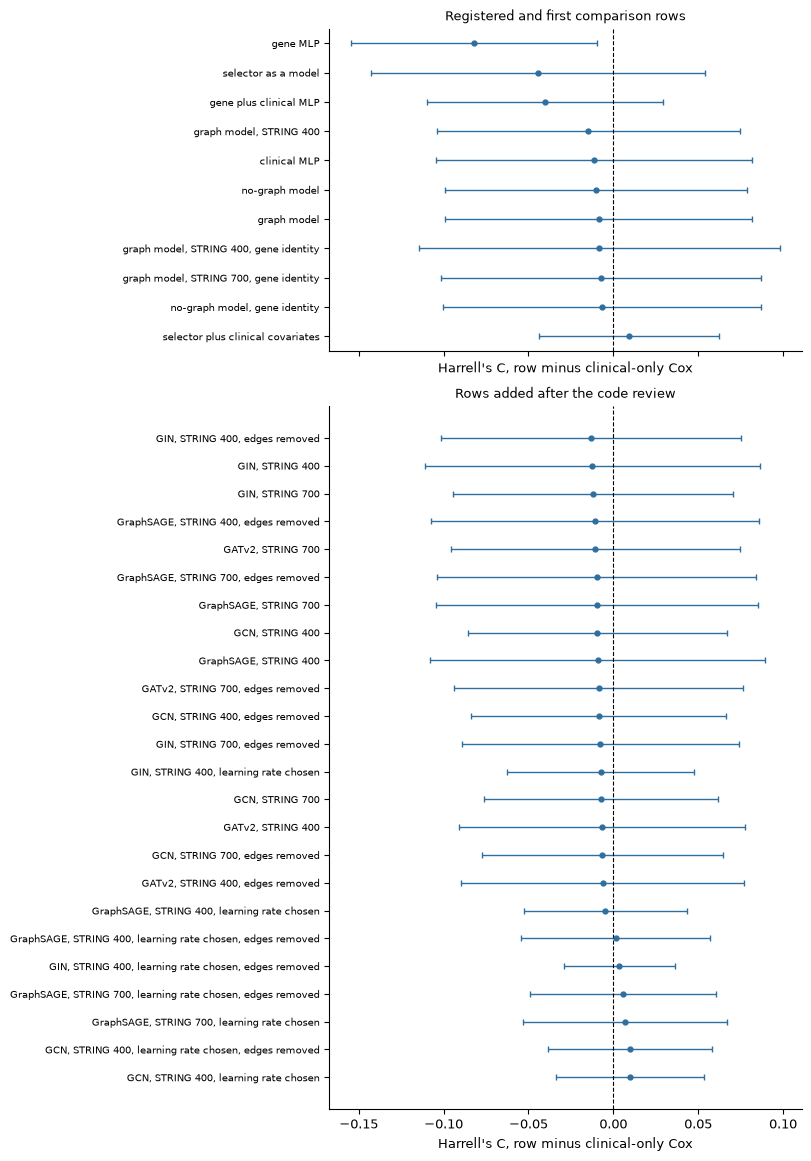

35 intervals against the clinical-only Cox; 1 of them exclude 0.

In [16]:
def trimmed(rows, words):
    """The same rows with a repeated part of their names left out, for shorter labels."""
    return rows.rename(index=lambda name: name.replace(words, ""))


against = paired[paired["question"] == "does a row beat the clinical-only Cox"]
after_review = "does a row added after the review beat the clinical-only Cox"
added = paired[paired["question"] == after_review]
figure, axes = plt.subplots(2, 1, figsize=(8, 11.5), height_ratios=[len(against), len(added)],
                            layout="constrained", sharex=True)
intervals(axes[0], trimmed(against, " minus clinical-only Cox").sort_values("mean difference"),
          "Registered and first comparison rows")
intervals(axes[1], trimmed(added, " minus clinical-only Cox").sort_values("mean difference"),
          "Rows added after the code review")
for axis in axes:
    axis.set_xlabel("Harrell's C, row minus clinical-only Cox")
save(figure, "figure_08_rows_against_clinical")
excluding = int((against["includes 0"] == "no").sum() + (added["includes 0"] == "no").sum())
display(Markdown(f"{len(against) + len(added)} intervals against the clinical-only Cox; "
                 f"{excluding} of them exclude 0."))

### Figure 9: the edges and the layer type

Left: each graph row minus the same row with every edge removed, registered rows first. Right: each layer type minus GraphSAGE at the same cut-off, and GraphSAGE on the GPU minus the registered CPU rows. The scale is much narrower than in figure 8.

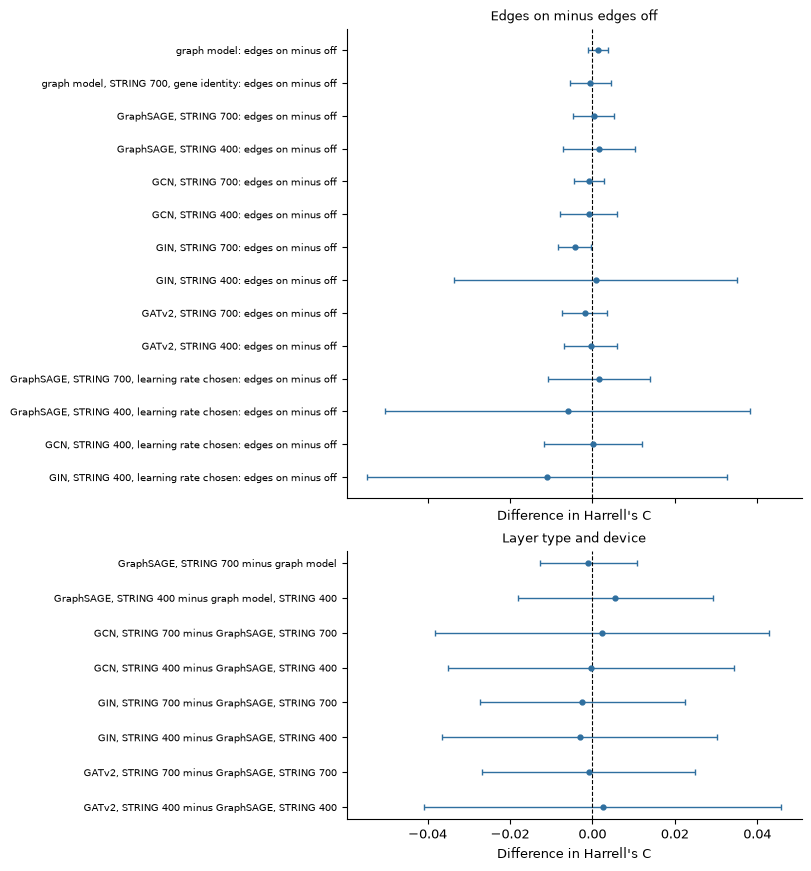

Edges: 13 of 14 intervals include 0. Layer type and device: 8 of 8 include 0.

In [17]:
edge_rows = paired[paired["question"].isin(["do the edges change the score",
                                            "do the edges change the score of each layer type"])]
layer_rows = paired[paired["question"].isin(["does the layer type change the score",
                                             "does the GPU reproduce the registered rows"])]
edge_rows = edge_rows.rename(index=lambda name: name.split(" minus ")[0] + ": edges on minus off")
panel_rows = [len(edge_rows), len(layer_rows)]
figure, axes = plt.subplots(2, 1, figsize=(8, 8.6), height_ratios=panel_rows,
                            layout="constrained", sharex=True)
intervals(axes[0], edge_rows, "Edges on minus edges off")
intervals(axes[1], layer_rows, "Layer type and device")
for axis in axes:
    axis.set_xlabel("Difference in Harrell's C")
save(figure, "figure_09_edges_and_layer_types")
display(Markdown(f"Edges: {int((edge_rows['includes 0'] == 'yes').sum())} of {len(edge_rows)} "
                 f"intervals include 0. Layer type and device: "
                 f"{int((layer_rows['includes 0'] == 'yes').sum())} of {len(layer_rows)} "
                 "include 0."))

### Figure 10: the training length

The registered graph model of each outer fold trained on its five inner folds only, at the registered learning rate and at ten times it: the mean over the 25 curves with one standard deviation shaded. The dashed line marks the registered number of updates.

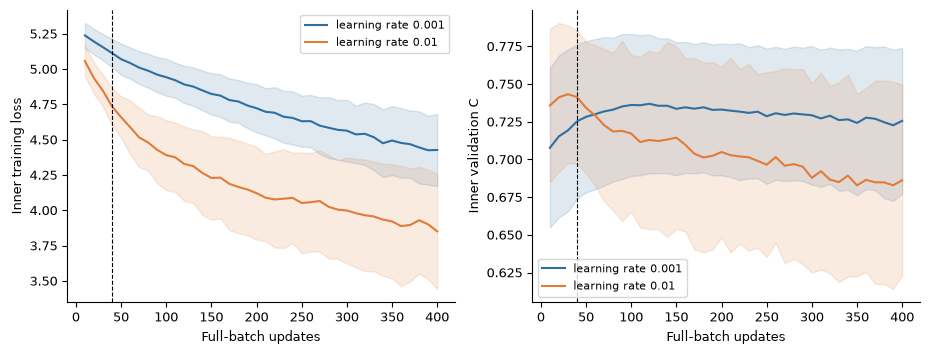

In [18]:
curve_points = []
for number in range(1, 6):
    record = json.loads((PIPELINE / "training_curve" / f"outer_fold_{number}.json").read_text())
    curve_points.extend(record["points"])
curve = pd.DataFrame(curve_points)
measures = curve.groupby(["learning rate", "update"])[["training loss", "validation C"]]
mean_curve = measures.mean()
spread_curve = measures.std()
curve_count = curve.groupby("learning rate")[["outer fold", "inner fold"]].apply(
    lambda part: len(part.drop_duplicates()))
assert (curve_count == 25).all(), "25 curves per learning rate, five inner folds per outer fold"
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for axis, measure in zip(axes, ["training loss", "validation C"]):
    for rate, colour in zip(sorted(curve["learning rate"].unique()), ["#2f6f9f", "#e07b39"]):
        middle = mean_curve.loc[rate, measure]
        band = spread_curve.loc[rate, measure]
        axis.plot(middle.index, middle, color=colour, label=f"learning rate {rate}")
        axis.fill_between(middle.index, middle - band, middle + band, color=colour, alpha=0.15)
    axis.axvline(REGISTERED_UPDATES, color="black", linestyle="--", linewidth=0.8)
    axis.set_xlabel("Full-batch updates")
    axis.set_ylabel(f"Inner {measure}")
    axis.legend(fontsize=8)
save(figure, "figure_10_training_curves")

In [19]:
registered = mean_curve.loc[(REGISTERED_RATE, REGISTERED_UPDATES), "validation C"]
best_rate, best_update = mean_curve["validation C"].idxmax()
slow = mean_curve.loc[REGISTERED_RATE, "validation C"]
display(Markdown(f"At learning rate {REGISTERED_RATE} the mean inner validation C is "
                 f"{registered:.3f} after {REGISTERED_UPDATES} updates and peaks at "
                 f"{slow.max():.3f} after {slow.idxmax()}; the best mean, "
                 f"{mean_curve['validation C'].max():.3f}, comes at rate {best_rate} after "
                 f"{best_update} updates."))

At learning rate 0.001 the mean inner validation C is 0.725 after 40 updates and peaks at 0.737 after 120; the best mean, 0.743, comes at rate 0.01 after 30 updates.

### Figure 11: the learning rate chosen on the inner folds

Each row that chose its learning rate (0.001 or 0.01) on the inner folds minus the same row at the registered rate, on the outer test parts.

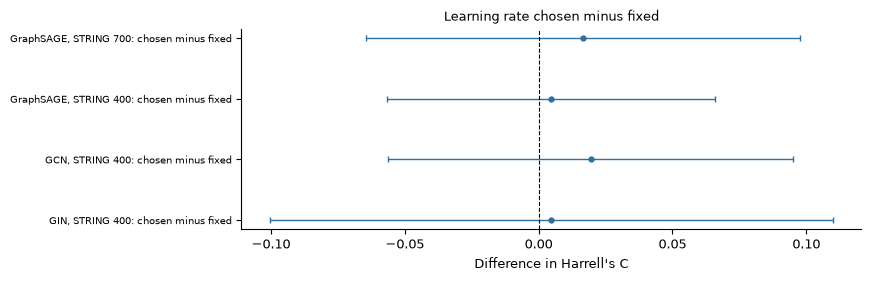

4 of 4 intervals include 0; the mean differences run from 0.005 to 0.019.

In [20]:
rate_rows = paired[paired["question"] == "does choosing the learning rate change the score"]
figure, axis = plt.subplots(figsize=(8, 2.6))
rate_labels = rate_rows.rename(index=lambda name: name.split(" minus ")[1] + ": chosen minus fixed")
intervals(axis, rate_labels, "Learning rate chosen minus fixed")
axis.set_xlabel("Difference in Harrell's C")
save(figure, "figure_11_learning_rate_rows")
display(Markdown(f"{int((rate_rows['includes 0'] == 'yes').sum())} of {len(rate_rows)} intervals "
                 "include 0; the mean differences run from "
                 f"{rate_rows['mean difference'].min():.3f} to "
                 f"{rate_rows['mean difference'].max():.3f}."))

### Figure 12: METABRIC, scored once

Left: Harrell's C for overall survival of every model fitted on all TCGA patients. Right: each model minus the clinical-only Cox with the 95% percentile interval over 2,000 resamples of METABRIC patients. These intervals cover patient sampling only, not the variation of training each model once.

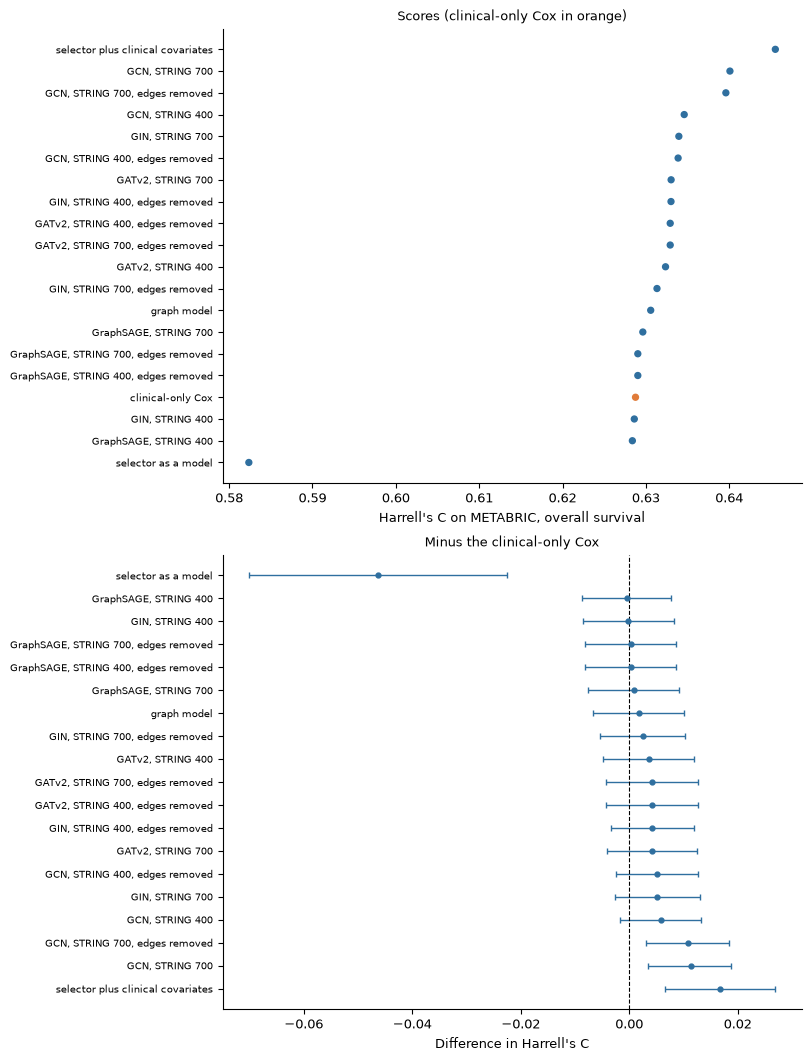

In [21]:
primary = "Harrell's C, overall survival"
ordered = metabric_scores[primary].sort_values()
against_clinical = metabric_paired[metabric_paired.index.str.endswith(" minus clinical-only Cox")]
renaming = {"difference": "mean difference"}  # the column name the interval plot reads
against_clinical = trimmed(against_clinical, " minus clinical-only Cox").rename(columns=renaming)
figure, axes = plt.subplots(2, 1, figsize=(8, 10.5), layout="constrained")
colours = np.where(ordered.index == "clinical-only Cox", "#e07b39", "#2f6f9f")
axes[0].scatter(ordered, range(len(ordered)), color=colours, s=18)
axes[0].set_yticks(range(len(ordered)), ordered.index, fontsize=7)
axes[0].set_xlabel("Harrell's C on METABRIC, overall survival")
axes[0].set_title("Scores (clinical-only Cox in orange)", fontsize=9)
intervals(axes[1], against_clinical.sort_values("mean difference"), "Minus the clinical-only Cox")
axes[1].set_xlabel("Difference in Harrell's C")
save(figure, "figure_12_metabric")

### Figure 13: follow-up in the two cohorts

Kaplan-Meier estimates of overall survival from the follow-up columns of the two cohort tables. TCGA's follow-up is short and most of its patients are censored early; METABRIC follows its patients for decades, and many of its deaths are from other causes.

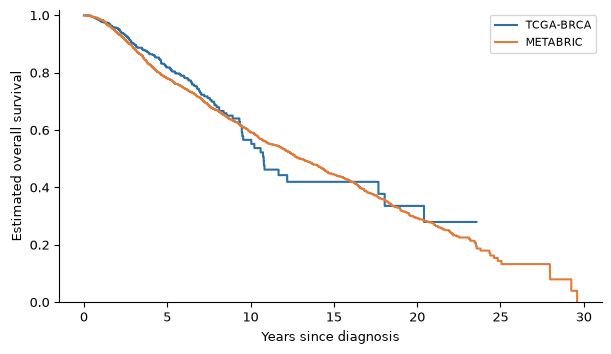

,0 years,5 years,10 years,15 years,20 years
TCGA-BRCA,1064,249,41,12,6
METABRIC,1979,1489,953,527,177


Patients still followed at 5 years: 249 of 1,064 in TCGA-BRCA and 1,489 of 1,979 in METABRIC.

In [22]:
def survival_curve(path):
    """The Kaplan-Meier estimate of overall survival, in years, from one cohort table."""
    table = pd.read_parquet(path, columns=["os_days", "os_event"])
    return kaplan_meier_estimator(table["os_event"].astype(bool),
                                  table["os_days"] / DAYS_PER_YEAR)


figure, axis = plt.subplots(figsize=(7, 3.8))
for name, label, colour in [("tcga", "TCGA-BRCA", "#2f6f9f"), ("metabric", "METABRIC", "#e07b39")]:
    times, survival = survival_curve(DATA / f"{name}.parquet")
    axis.step(times, survival, where="post", color=colour, label=label)
axis.set_xlabel("Years since diagnosis")
axis.set_ylabel("Estimated overall survival")
axis.set_ylim(0, 1.02)
axis.legend(fontsize=8)
save(figure, "figure_13_follow_up")
followed = {}
for name, label in [("tcga", "TCGA-BRCA"), ("metabric", "METABRIC")]:
    days = pd.read_parquet(DATA / f"{name}.parquet", columns=["os_days"])["os_days"]
    years = days / DAYS_PER_YEAR
    counts_at = []
    for point in AT_RISK_YEARS:
        counts_at.append(int((years >= point).sum()))
    followed[label] = counts_at
at_risk = pd.DataFrame(followed, index=[f"{point} years" for point in AT_RISK_YEARS]).T
display(at_risk)
display(Markdown(f"Patients still followed at {AT_RISK_YEARS[1]} years: "
                 f"{at_risk.iloc[0, 1]:,} of {at_risk.iloc[0, 0]:,} in TCGA-BRCA and "
                 f"{at_risk.iloc[1, 1]:,} of {at_risk.iloc[1, 0]:,} in METABRIC."))

## Run record

The git commit, the package versions, the layout seed, the hashes of the files the figures read, and the figure files written.

In [23]:
def sha256(path):
    """The sha256 of one file."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


inputs = [RESULTS / "01_data" / "cohort_tcga.csv", RESULTS / "01_data" / "cohort_metabric.csv",
          RESULTS / "02_gene_graph" / "graph_summary.csv", PIPELINE / "summary.csv",
          PIPELINE / "comparison_paired.csv", PIPELINE / "comparison_by_fold.csv",
          PIPELINE / "final_model" / "model.pt", PIPELINE / "metabric" / "scores.csv",
          PIPELINE / "metabric" / "paired.csv", DATA / "tcga.parquet", DATA / "metabric.parquet"]
hashes = {}
for path in inputs:
    hashes[str(path.relative_to(".."))] = sha256(path)
packages = {}
for name in ["matplotlib", "networkx", "numpy", "pandas", "scikit-survival", "torch"]:
    packages[name] = version(name)
command = ["git", "status", "--porcelain", "--untracked-files=no"]
changed = subprocess.run(command, capture_output=True, text=True, check=True).stdout.splitlines()
commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                        check=True).stdout.rstrip()
figures = sorted(path.name for path in OUT.glob("figure_*.png"))
run_record = {"git commit": commit, "tracked files changed since that commit": changed,
              "python": sys.version.split()[0], "packages": packages,
              "seeds": {"spring layout": LAYOUT_SEED}, "input files (sha256)": hashes,
              "figures": figures}
(OUT / "run_record.json").write_text(json.dumps(run_record, indent=1) + "\n")
display(Markdown(f"Commit {commit[:7]}; {len(figures)} figures written; {len(hashes)} input "
                 "files hashed."))

Commit eb78519; 13 figures written; 11 input files hashed.